# Practical 11: Continuous Predictive Modeling with Linear Regression

**UNIT 3: Preparing Big Data for Machine Learning**

**Problem Statement:** Write a Python program to build, train, and evaluate a Linear Regression model using Scikit-Learn. Fit the model to predict salary based on years of experience, display model coefficients (slope and intercept), predict outcomes on the test dataset, and calculate Mean Squared Error (MSE) and R-squared (R2) score.

,YearsExperience,Salary
0,1.1,44760.0
1,1.4,35146.0
2,2.3,51893.0
3,2.4,55025.0
4,2.5,58768.0


Train size: 24 | Test size: 8
Slope (coefficient): 10,726.27   -> salary rises by this much per extra year
Intercept           : 29,628.84
Equation            : Salary = 29,628.84 + 10,726.27 x Experience

,Experience,Actual,Predicted
0,7.4,107570.0,109003.0
1,1.1,44760.0,41428.0
2,7.6,105945.0,111149.0
3,6.9,104110.0,103640.0
4,7.5,108283.0,110076.0
5,5.0,80572.0,83260.0
6,2.5,62194.0,56445.0
7,1.4,35146.0,44646.0


MSE  : 21,774,436.70
RMSE : 4,666.31
R²   : 0.9727
Predicted salary for 4.5 years of experience: 77,897

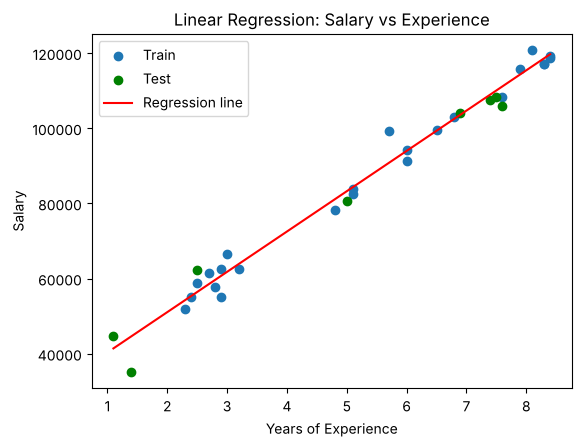

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

rnd = np.random.default_rng(123)
n = 32
x_years = np.sort(np.round(rnd.uniform(1, 9, n), 1))
salary = np.round(28000 + 11000 * x_years + rnd.normal(0, 3800, n), 0)
tbl = pd.DataFrame({"YearsExperience": x_years, "Salary": salary})
print(tbl.head())

X = tbl[["YearsExperience"]]
y = tbl["Salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=21)
print("Train size:", len(X_train), "| Test size:", len(X_test))

reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

print(f"Slope (coefficient): {reg_model.coef_[0]:,.2f}   -> salary rises by this much per extra year")
print(f"Intercept           : {reg_model.intercept_:,.2f}")
print(f"Equation            : Salary = {reg_model.intercept_:,.2f} + {reg_model.coef_[0]:,.2f} x Experience")

y_pred = reg_model.predict(X_test)
actual_vs_pred = pd.DataFrame({"Experience": X_test["YearsExperience"].values,
                           "Actual": y_test.values,
                           "Predicted": y_pred.round(0)})
print(actual_vs_pred)

mse = mean_squared_error(y_test, y_pred)
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : {np.sqrt(mse):,.2f}")
print(f"R²   : {r2_score(y_test, y_pred):.4f}")

new = pd.DataFrame({"YearsExperience": [4.5]})
print(f"Predicted salary for 4.5 years of experience: {reg_model.predict(new)[0]:,.0f}")

plt.scatter(X_train, y_train, label="Train")
plt.scatter(X_test, y_test, color="green", label="Test")
plt.plot(X, reg_model.predict(X), color="red", label="Regression line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression: Salary vs Experience")
plt.legend()
plt.show()